# Machine Learning Final Project: 
## Neuro-Symbolic Differentiable Rule Extractor (NSDRE)

**Creator**: Iman Sharifi, G46454668

## Network

In [10]:
from ANDRE_Net import ANDRE

Num Rules: 1, Restart 1/1, Final Loss: 0.5594.
Num Rules: 2, Restart 1/1, Final Loss: 0.1218.


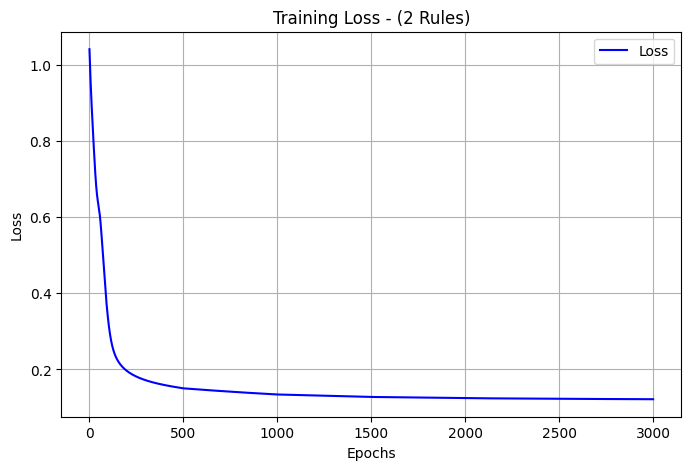

The most repeated rule is: 'h1 :- b3 and b4.'
Accuracy over training data: 0.993.
The most repeated rule is: 'h2 :- b1 and not(b2).'
Accuracy over training data: 0.984.

Final Rule:
h :- b3 and b4 OR b1 and not(b2).


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from ANDRE_Net import ANDRE
from collections import Counter
from utils import interpret_neuron_weights_entropy
# Parameters
Num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000
num_epochs = 3000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# define y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float() using &
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        model_nsre = ANDRE(num_rules + 1, pot_body_pred_dim=input_dim, variable_matrix=None)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            total_loss = bce_loss + entropy_weight * entropy_term #+ similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

# Load the best model
best_model = ANDRE(best_num_rules, pot_body_pred_dim=input_dim, variable_matrix=None)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
# print("\nFinal Weights of the Network:")
# for i, weights in enumerate(Weights_nsre):
#     print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


# Network for Structured Rules

V_matrix:
 tensor([[1., 1., 0.],
        [1., 0., 0.],
        [0., 1., 1.],
        [1., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/1 Final Loss: 0.1007


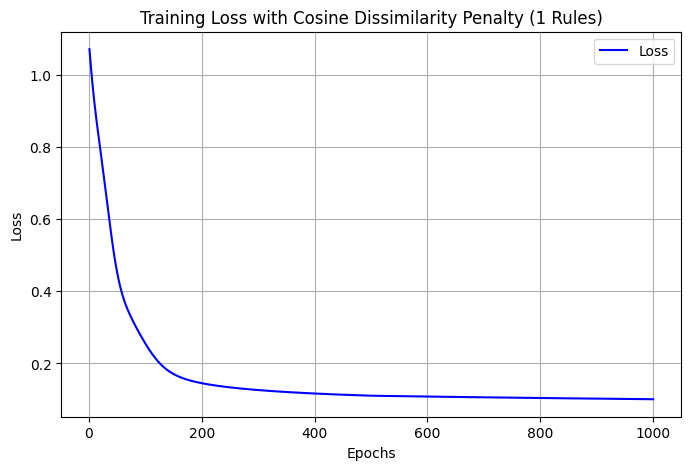

The most repeated rule is: 'h1 :- not(b1(X1, X2)) and b3(X2, X3).'
Accuracy over training data: 0.95.

Final Rule:
h :- not(b1(X1, X2)) and b3(X2, X3).

Final M matrices:
M1: [1.4966949224472046, 1.9435255527496338, 1.243132472038269]


In [11]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
from utils import create_V_matrix, interpret_neuron_weights_entropy_

# Parameters
num_rules = 1
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 500
num_epochs = 1000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
y_train = (((1 - X_train[:, 0]) > 0.5) & (X_train[:, 2] > 0.5)).float()

# Body predicates and their variables
# B = {b1(X1, X2), b2(X1), b3(X2, X3), b4(X1, X3)}
predicates = ["b1(X1, X2)", "b2(X1)", "b3(X2, X3)", "b4(X1, X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

head_vars = [0, 2] # X1 and X3 are the head variables
connected_vars = [1]  # X2 is the only auxiliary variable


# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)

        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        # The only auxiliary variable is X2
        M_connected = [M[i][connected_vars] for i in range(num_rules)]

        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        import math
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty + entropy_weight * entropy_term + 0.1 * range_restricted_loss + 0.1 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {M}")

## What if we have more than one rule?

V_matrix:
 tensor([[1., 1., 0.],
        [0., 1., 1.],
        [1., 0., 0.],
        [0., 0., 1.]])
Variable order: ['X1', 'X2', 'X3']
Restart 1/3 Final Loss: 0.1156
Restart 2/3 Final Loss: 0.1155
Restart 3/3 Final Loss: 0.1156


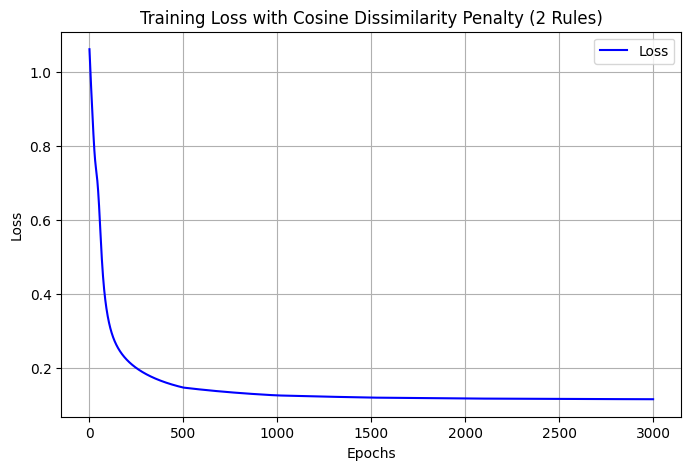


Final M matrices:
M1: [1. 0. 1.]
M2: [1. 2. 1.]

Final V matrix:
[[1. 1. 0.]
 [0. 1. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]
The most repeated rule is: 'h1 :- b3(X1) and b4(X3).'
Accuracy over training data: 0.988.
The most repeated rule is: 'h2 :- b1(X1, X2) and not(b2(X2, X3)).'
Accuracy over training data: 0.993.

Final Rule:
h :- b3(X1) and b4(X3) OR b1(X1, X2) and not(b2(X2, X3)).


In [13]:
# Re-execution after kernel reset

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import Counter
import math
import numpy as np

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = num_neurons_per_rule
num_samples = 2000
num_epochs = 3000
num_restarts = 3
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
# put the second column same as the first column
# X_train[:, 1] = X_train[:, 0]
# y_train = (((1 - X_train[:, 0]) * X_train[:, 1] > 0.25) | ((X_train[:, 2] * X_train[:, 3]) > 0.25)).float()
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Target body predicates and their variables
# B = {b1(X1, X2), b2(X2, X3), b3(X1), b4(X3)}
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["b1(X1, X2)", "b2(X2, X3)", "b3(X1)", "b4(X3)"]
V_matrix, variable_order = create_V_matrix(predicates)
print("V_matrix:\n", V_matrix)
print("Variable order:", variable_order)

# Variables
variables = ["X1", "X2", "X3"]  # Assuming we have 3 variables
# Head variables for the rule
head_variables = ["X1", "X3"]  # Assuming the head variables are X1 and X3
# Define head variables indices
# Assuming the head variables are X1 and X3, we can define their indices
head_vars = [0, 2]  # Assuming the head variables are X1 and X3
connected_vars = [1]  # Assuming X2 is the only auxiliary variable

# print("V_matrix:\n", V_matrix)
# print("Variable order:", variable_order)

# Cosine similarity
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=V_matrix)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Compute range resticted loss -> the probability of the head variables being present in the rule
        M = model_nsre.M_matrices
        # Find the corresponding values of M to head variables (here Variable 1 and 3)
        M_head = [M[i][head_vars] for i in range(num_rules)]
        # Multiply the elements of M_head
        head_var_probs = torch.prod(torch.stack(M_head), dim=0)
        # Find the loss as the mean of the head variable probabilities with 1 (the probability of the head variable being present)
        range_restricted_loss = torch.mean(torch.sigmoid(-10 * (head_var_probs - 0.5)))
        # print(f"Range Restricted Loss: {range_restricted_loss.item()}")

        # Compute the connected loss -> auxiliary variables should be present in the rule either zero or more than one time
        M_connected = [M[i][connected_vars] for i in range(num_rules)]
        # Compute this for each auxiliary variable: F(x) = normal distribution with mean 1 and std 0.2
        Sum_Fx = 0.0
        for i, M in enumerate(M_connected):
            mean = 1.0
            std = 0.2
            Sum_Fx += torch.exp(-0.5 * ((M - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))
        connected_loss = 0.5 * Sum_Fx / len(M_connected)  # Average over all rules

        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty + entropy_weight * entropy_term + 0.01 * range_restricted_loss + 0.01 * connected_loss
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

        # print V matrix
        # print("V matrix:", model_nsre.V.detach().numpy())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load best model and compute M
best_model = ANDRE(num_rules, pot_body_pred_dim=input_dim, variable_matrix=V_matrix)
best_model.load_state_dict(best_state_dict)
_ = best_model(X_train)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]
V_matrix = best_model.V.detach().numpy().tolist()

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")

print("\nFinal V matrix:")
print(np.round(V_matrix))

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")
